In [4]:
%pip install pandas numpy matplotlib seaborn joblib scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)


# 1.Load Dataset

In [7]:
df = pd.read_csv(r'C:\Users\Krupa\Downloads\NEXUS_Smart_Business_Analysis_200000_Records.csv')
df

,record_id,date,store_id,region,business_type,product_category,season,units_sold,unit_price_inr,discount_pct,...,inventory_level,competitor_price_inr,economic_index,revenue_inr,cost_inr,profit_inr,profit_margin_pct,next_month_sales_units,sales_growth_pct,demand_level
0,1,24-07-2023,ST352,North,E-commerce,Sports,Summer,274,1893.14,17.19,...,2203,1874.39,107.74,429569.27,318736.52,110832.75,25.80,342,24.82,Medium
1,2,23-12-2022,ST361,Central,E-commerce,Electronics,Winter,99,9812.98,13.28,...,1418,9284.40,92.88,842506.43,601182.00,241324.44,28.64,69,-30.30,Low
2,3,26-11-2026,ST190,Central,E-commerce,Beauty,Autumn,678,722.42,8.63,...,146,763.03,101.12,447539.44,307204.53,140334.91,31.36,944,39.23,High
3,4,03-02-2024,ST295,Central,Retail,Sports,Winter,335,1780.69,13.53,...,1937,2197.33,108.44,515832.55,367119.63,148712.92,28.83,808,141.19,High
4,5,28-01-2026,ST094,South,Manufacturing,Home & Furniture,Winter,101,7371.66,22.14,...,938,6238.29,98.61,579708.18,403370.39,176337.80,30.42,120,18.81,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199995,199996,04-01-2023,ST450,Central,Retail,Electronics,Winter,504,7259.80,11.60,...,2051,6196.76,111.42,3234683.67,2410202.63,824481.04,25.49,598,18.65,High
199996,199997,15-05-2024,ST499,South,Food & Beverage,Home & Furniture,Spring,585,8180.63,3.69,...,859,9045.26,106.27,4609122.71,2286940.68,2322182.03,50.38,943,61.20,High
199997,199998,10-07-2026,ST082,South,E-commerce,Electronics,Summer,448,8937.14,6.49,...,1440,9907.14,100.43,3744147.71,2125909.98,1618237.73,43.22,878,95.98,High
199998,199999,26-01-2024,ST027,North,Retail,Beauty,Winter,127,970.50,2.16,...,1047,1106.72,107.15,120585.12,160141.23,-39556.11,-32.80,263,107.09,Medium


# 2.Display first 5 Records


In [8]:
print("First 5 Records:")
print(df.head())

First 5 Records:
   record_id        date store_id   region  business_type  product_category  \
0          1  24-07-2023    ST352    North     E-commerce            Sports   
1          2  23-12-2022    ST361  Central     E-commerce       Electronics   
2          3  26-11-2026    ST190  Central     E-commerce            Beauty   
3          4  03-02-2024    ST295  Central         Retail            Sports   
4          5  28-01-2026    ST094    South  Manufacturing  Home & Furniture   

   season  units_sold  unit_price_inr  discount_pct  ...  inventory_level  \
0  Summer         274         1893.14         17.19  ...             2203   
1  Winter          99         9812.98         13.28  ...             1418   
2  Autumn         678          722.42          8.63  ...              146   
3  Winter         335         1780.69         13.53  ...             1937   
4  Winter         101         7371.66         22.14  ...              938   

   competitor_price_inr  economic_index  reve

# 3.Display last 5 Records

In [9]:
print("\nLast 5 Records:")
print(df.tail())


Last 5 Records:
        record_id        date store_id   region    business_type  \
199995     199996  04-01-2023    ST450  Central           Retail   
199996     199997  15-05-2024    ST499    South  Food & Beverage   
199997     199998  10-07-2026    ST082    South       E-commerce   
199998     199999  26-01-2024    ST027    North           Retail   
199999     200000  07-06-2024    ST453  Central        Wholesale   

        product_category  season  units_sold  unit_price_inr  discount_pct  \
199995       Electronics  Winter         504         7259.80         11.60   
199996  Home & Furniture  Spring         585         8180.63          3.69   
199997       Electronics  Summer         448         8937.14          6.49   
199998            Beauty  Winter         127          970.50          2.16   
199999            Sports  Summer         304         1581.43          2.98   

        ...  inventory_level  competitor_price_inr  economic_index  \
199995  ...             2051       

# 4.Data Shape

In [10]:
print("\nDataset Shape:")
print(df.shape)



Dataset Shape:
(200000, 23)


# 5.Dataset Information

In [11]:
print("\nDataset Information:")
print(df.info())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 23 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   record_id               200000 non-null  int64  
 1   date                    200000 non-null  str    
 2   store_id                200000 non-null  str    
 3   region                  200000 non-null  str    
 4   business_type           200000 non-null  str    
 5   product_category        200000 non-null  str    
 6   season                  200000 non-null  str    
 7   units_sold              200000 non-null  int64  
 8   unit_price_inr          200000 non-null  float64
 9   discount_pct            200000 non-null  float64
 10  marketing_spend_inr     200000 non-null  float64
 11  website_visits          200000 non-null  int64  
 12  customer_count          200000 non-null  int64  
 13  inventory_level         200000 non-null  int64  
 14  competito

# 6.Check Missing Values

In [12]:
print("\nMissing Values:")
print(df.isnull().sum())



Missing Values:
record_id                 0
date                      0
store_id                  0
region                    0
business_type             0
product_category          0
season                    0
units_sold                0
unit_price_inr            0
discount_pct              0
marketing_spend_inr       0
website_visits            0
customer_count            0
inventory_level           0
competitor_price_inr      0
economic_index            0
revenue_inr               0
cost_inr                  0
profit_inr                0
profit_margin_pct         0
next_month_sales_units    0
sales_growth_pct          0
demand_level              0
dtype: int64


# 7.Check Duplicates

In [13]:
print("\nDuplicate Records:")
print(df.duplicated().sum())



Duplicate Records:
0


# 8.Data Preprocessing

In [14]:
df.columns = df.columns.str.strip()

df = df.drop_duplicates()

df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df['month'] = df['date'].dt.month
df['year'] = df['date'].dt.year

df = df.dropna(subset=['demand_level'])

# Remove ID and future information to avoid data leakage
df = df.drop(
    ['record_id', 'store_id', 'date',
     'next_month_sales_units', 'sales_growth_pct'],
    axis=1
)

print("\nPreprocessed Dataset:")
print(df.head())



Preprocessed Dataset:
    region  business_type  product_category  season  units_sold  \
0    North     E-commerce            Sports  Summer         274   
1  Central     E-commerce       Electronics  Winter          99   
2  Central     E-commerce            Beauty  Autumn         678   
3  Central         Retail            Sports  Winter         335   
4    South  Manufacturing  Home & Furniture  Winter         101   

   unit_price_inr  discount_pct  marketing_spend_inr  website_visits  \
0         1893.14         17.19             51285.84           46803   
1         9812.98         13.28              1673.52           33550   
2          722.42          8.63             12067.32           79788   
3         1780.69         13.53            105409.74           79264   
4         7371.66         22.14             23082.07           51374   

   customer_count  inventory_level  competitor_price_inr  economic_index  \
0             163             2203               1874.39         

# 9.Separate Features and Target

In [15]:
X = df.drop('demand_level', axis=1)
y = df['demand_level']


# 10.Identify Numerical and Categorical Columns



In [16]:
num_cols = X.select_dtypes(include=np.number).columns

cat_cols = X.select_dtypes(include='object').columns


C:\Users\Krupa\AppData\Local\Temp\ipykernel_22480\1437457408.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns


# 11.Data Transformation


In [17]:
num_process = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_process = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', num_process, num_cols),
    ('cat', cat_process, cat_cols)
])


# 11.Train-Test Split


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)



Training Data: (160000, 19)
Testing Data: (40000, 19)


# 12.Create Random Forest Model

In [19]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])


# 13.Model Training

In [20]:
model.fit(X_train, y_train)
print("\nModel Training Completed Successfully!")


Model Training Completed Successfully!


# 14. Model Testing and Prediction

In [21]:
y_pred = model.predict(X_test)

print("\nPredicted Values:")
print(y_pred[:20])



Predicted Values:
['Medium' 'High' 'Medium' 'High' 'Medium' 'Medium' 'Medium' 'Medium'
 'High' 'Medium' 'Low' 'High' 'High' 'High' 'High' 'Low' 'Medium' 'High'
 'High' 'Medium']


# 15.Calculate Model Accuracy


In [22]:
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")


Model Accuracy: 91.79 %


# 16.Model Evaluation


In [23]:
print("\nPrecision:",
      round(precision_score(y_test, y_pred,
                            average='weighted'), 4))

print("\nRecall:",
      round(recall_score(y_test, y_pred,
                         average='weighted'), 4))

print("\nF1 Score:",
      round(f1_score(y_test, y_pred,
                     average='weighted'), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))




Precision: 0.9171

Recall: 0.9179

F1 Score: 0.9174

Classification Report:
              precision    recall  f1-score   support

        High       0.95      0.96      0.95     25055
         Low       0.93      0.89      0.91      5442
      Medium       0.84      0.81      0.82      9503

    accuracy                           0.92     40000
   macro avg       0.90      0.89      0.90     40000
weighted avg       0.92      0.92      0.92     40000



# 17.Confusion Matrix

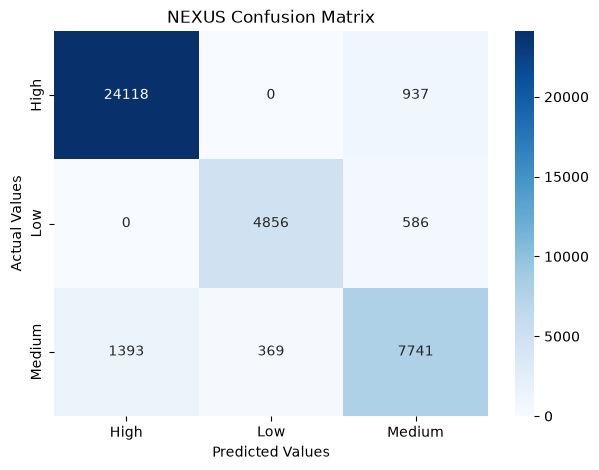

In [24]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.title("NEXUS Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()


# 18.Accuracy Graph

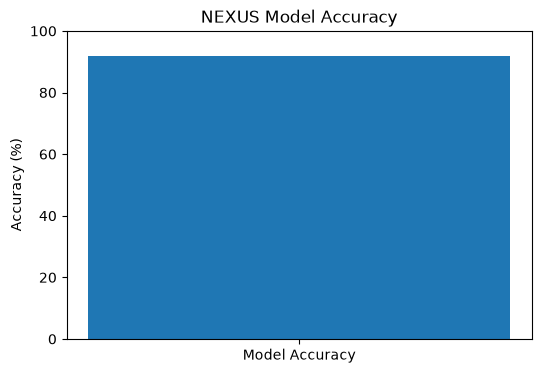

In [25]:
plt.figure(figsize=(6, 4))

plt.bar(
    ['Model Accuracy'],
    [accuracy * 100]
)

plt.title("NEXUS Model Accuracy")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()



# 19.Actual vs Predicted Comparison

In [26]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(20))



Actual vs Predicted:
    Actual Predicted
0     High    Medium
1     High      High
2   Medium    Medium
3     High      High
4   Medium    Medium
5   Medium    Medium
6   Medium    Medium
7   Medium    Medium
8     High      High
9   Medium    Medium
10     Low       Low
11  Medium      High
12    High      High
13    High      High
14    High      High
15     Low       Low
16  Medium    Medium
17    High      High
18    High      High
19  Medium    Medium


# 20.Feature Importance

In [ ]:
feature_names = model.named_steps[
    'preprocessor'
].get_feature_names_out()

importance = model.named_steps[
    'classifier'
].feature_importances_

feature_importance = pd.Series(
    importance,
    index=feature_names
).sort_values(ascending=False)

print("\nTop 10 Important Features:")
print(feature_importance.head(10))

feature_importance.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Top 10 Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()


# Save Trained Model


In [ ]:
joblib.dump(model, 'NEXUS_Trained_Model.pkl')

print("\nModel Saved Successfully!")



Model Saved Successfully!


# 21.Monthly Sales Trend by Product


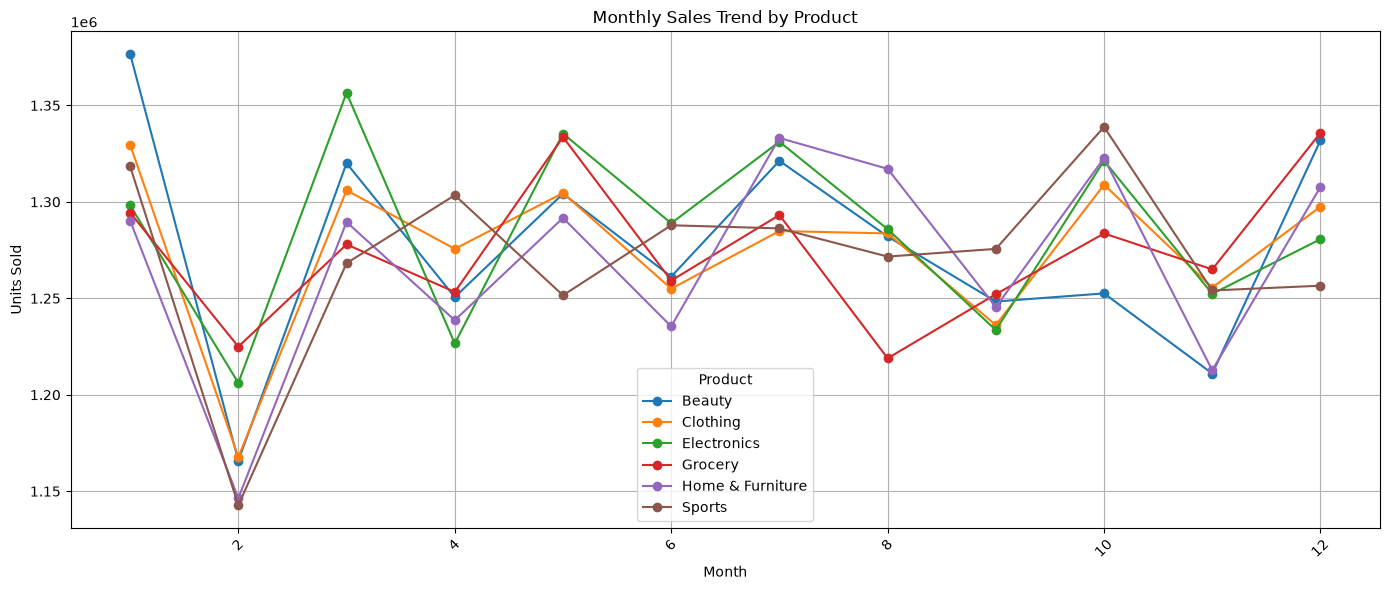

In [ ]:
monthly_product_sales = df.pivot_table(
    index='month',
    columns='product_category',
    values='units_sold',
    aggfunc='sum'
)

monthly_product_sales.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title("Monthly Sales Trend by Product")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.legend(title="Product")
plt.grid()
plt.tight_layout()
plt.show()


# 22.Monthly Sales Contribution by Product

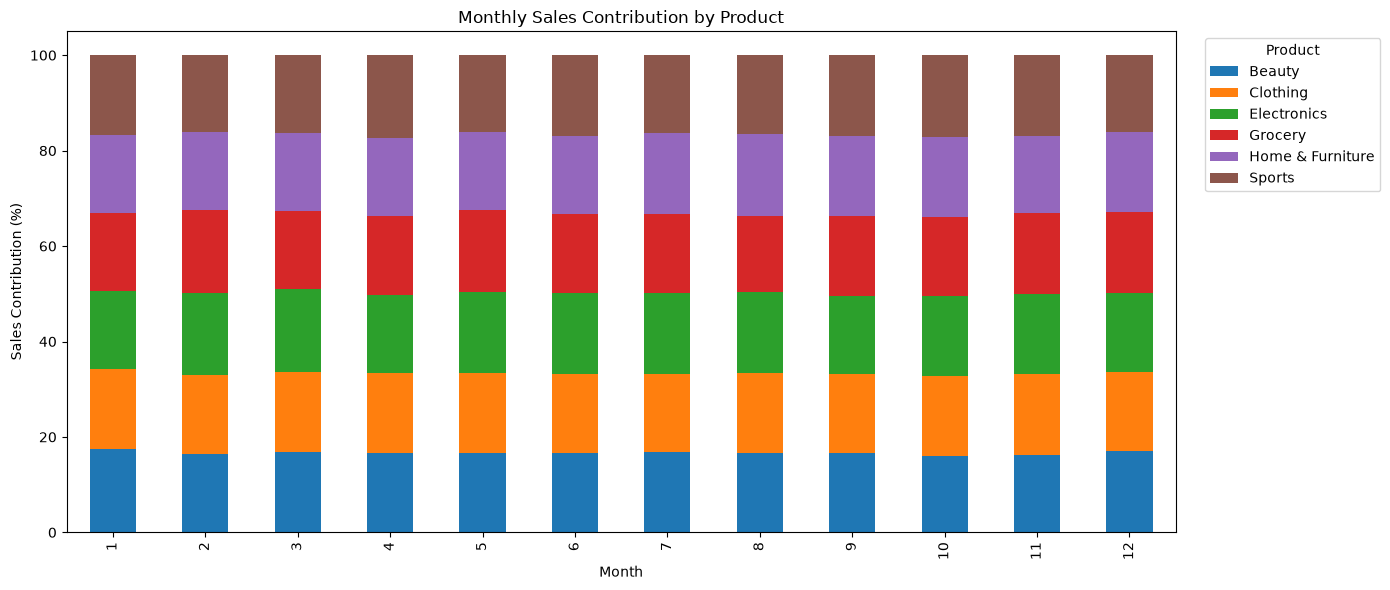

In [ ]:
monthly_contribution = df.pivot_table(
    index='month',
    columns='product_category',
    values='units_sold',
    aggfunc='sum'
)

monthly_percentage = monthly_contribution.div(
    monthly_contribution.sum(axis=1), axis=0
) * 100

monthly_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 6)
)

plt.title("Monthly Sales Contribution by Product")
plt.xlabel("Month")
plt.ylabel("Sales Contribution (%)")
plt.xticks(rotation=90)
plt.legend(title="Product", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# 23.Highest and Lowest Product Sales


Product Sales Ranking:
product_category
Electronics         15416486
Beauty              15325837
Clothing            15305200
Grocery             15291965
Sports              15255183
Home & Furniture    15230770
Name: units_sold, dtype: int64

Highest Selling Product: Electronics
Highest Sales: 15416486

Lowest Selling Product: Home & Furniture
Lowest Sales: 15230770


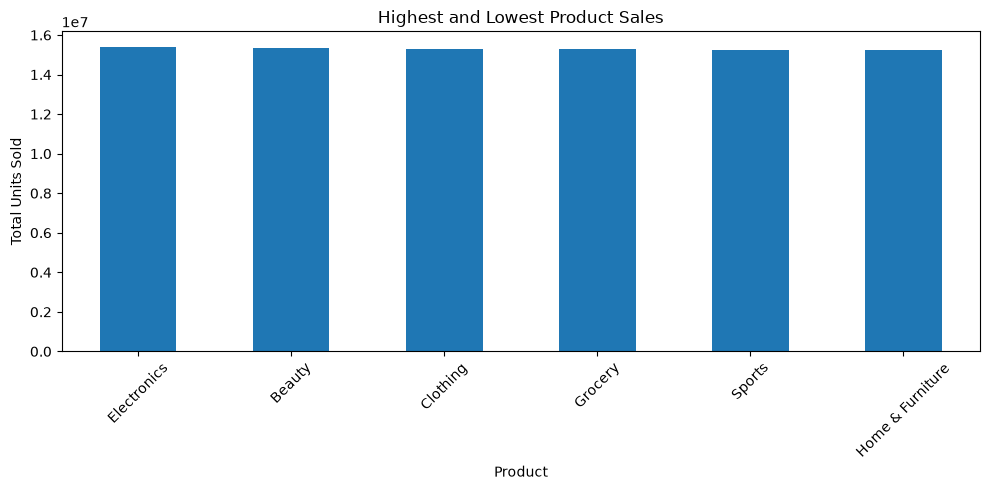

In [ ]:
product_sales = df.groupby(
    'product_category'
)['units_sold'].sum().sort_values(ascending=False)

print("\nProduct Sales Ranking:")
print(product_sales)

highest = product_sales.idxmax()
lowest = product_sales.idxmin()

print("\nHighest Selling Product:", highest)
print("Highest Sales:", product_sales.max())

print("\nLowest Selling Product:", lowest)
print("Lowest Sales:", product_sales.min())

product_sales.plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Highest and Lowest Product Sales")
plt.xlabel("Product")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# 24.Which Month Has the Highest Sales?


Highest Sales Month: 1
Highest Monthly Sales: 7907482

Lowest Sales Month: 2
Lowest Monthly Sales: 7053750


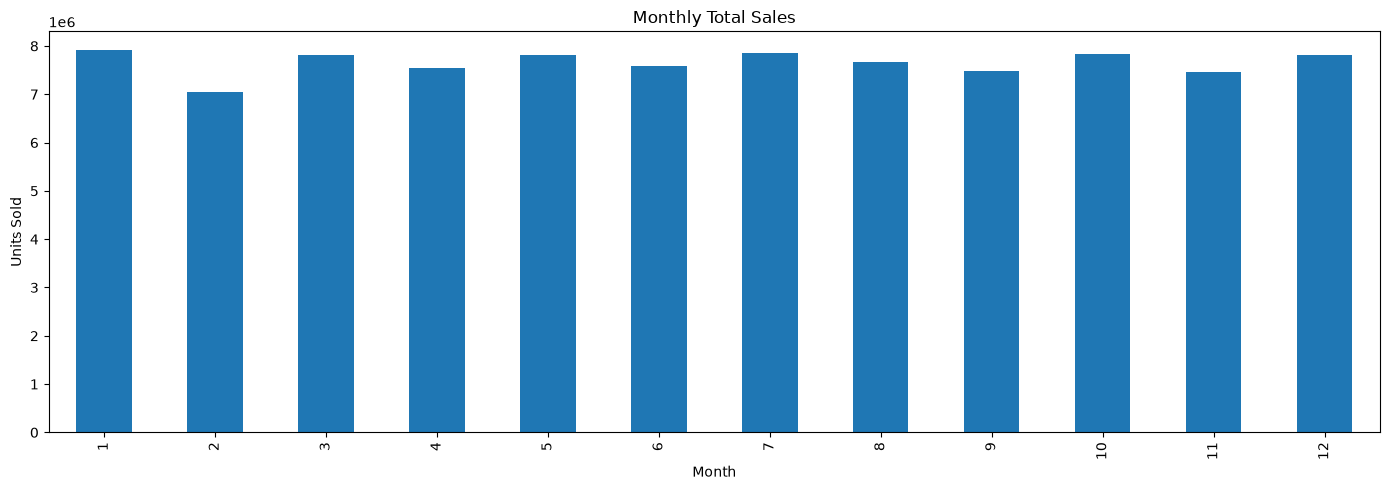

In [ ]:
monthly_sales = df.groupby('month')['units_sold'].sum()

highest_sales_month = monthly_sales.idxmax()
lowest_sales_month = monthly_sales.idxmin()

print("\nHighest Sales Month:", highest_sales_month)
print("Highest Monthly Sales:", monthly_sales.max())

print("\nLowest Sales Month:", lowest_sales_month)
print("Lowest Monthly Sales:", monthly_sales.min())

monthly_sales.plot(
    kind='bar',
    figsize=(14, 5)
)

plt.title("Monthly Total Sales")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


# 25.Which Month Has Maximum Profit?


Maximum Profit Month: 7
Maximum Profit: 6885126574.33

Minimum Profit Month: 2
Minimum Profit: 6079457453.29


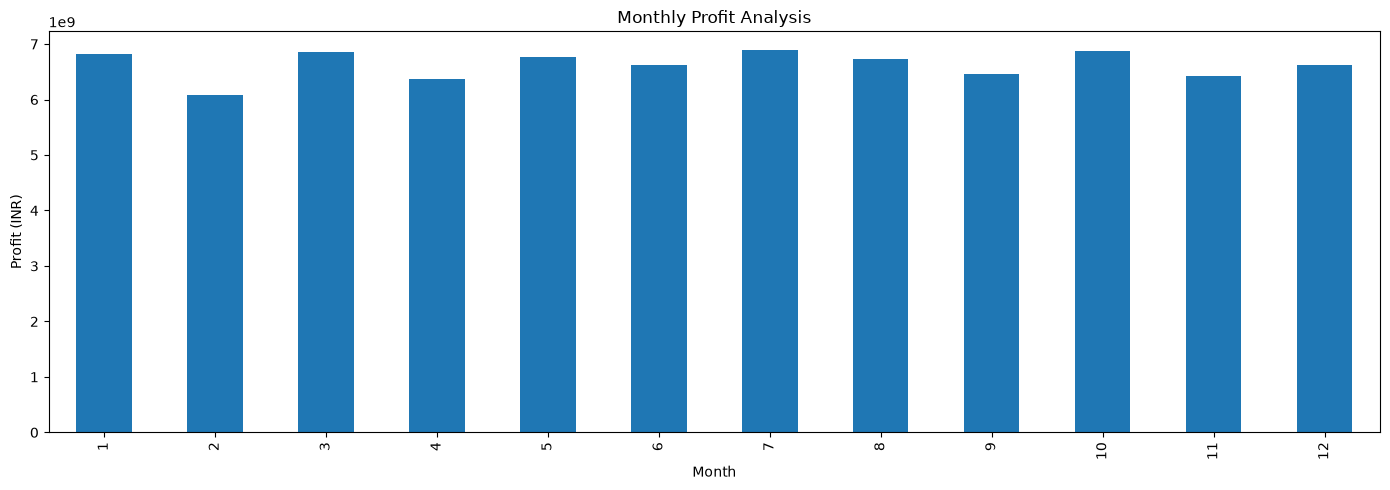

In [ ]:
monthly_profit = df.groupby('month')['profit_inr'].sum()

maximum_profit_month = monthly_profit.idxmax()
minimum_profit_month = monthly_profit.idxmin()

print("\nMaximum Profit Month:", maximum_profit_month)
print("Maximum Profit:", monthly_profit.max())

print("\nMinimum Profit Month:", minimum_profit_month)
print("Minimum Profit:", monthly_profit.min())

monthly_profit.plot(
    kind='bar',
    figsize=(14, 5)
)

plt.title("Monthly Profit Analysis")
plt.xlabel("Month")
plt.ylabel("Profit (INR)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

# 26.Monthly Revenue vs Profit Comparison

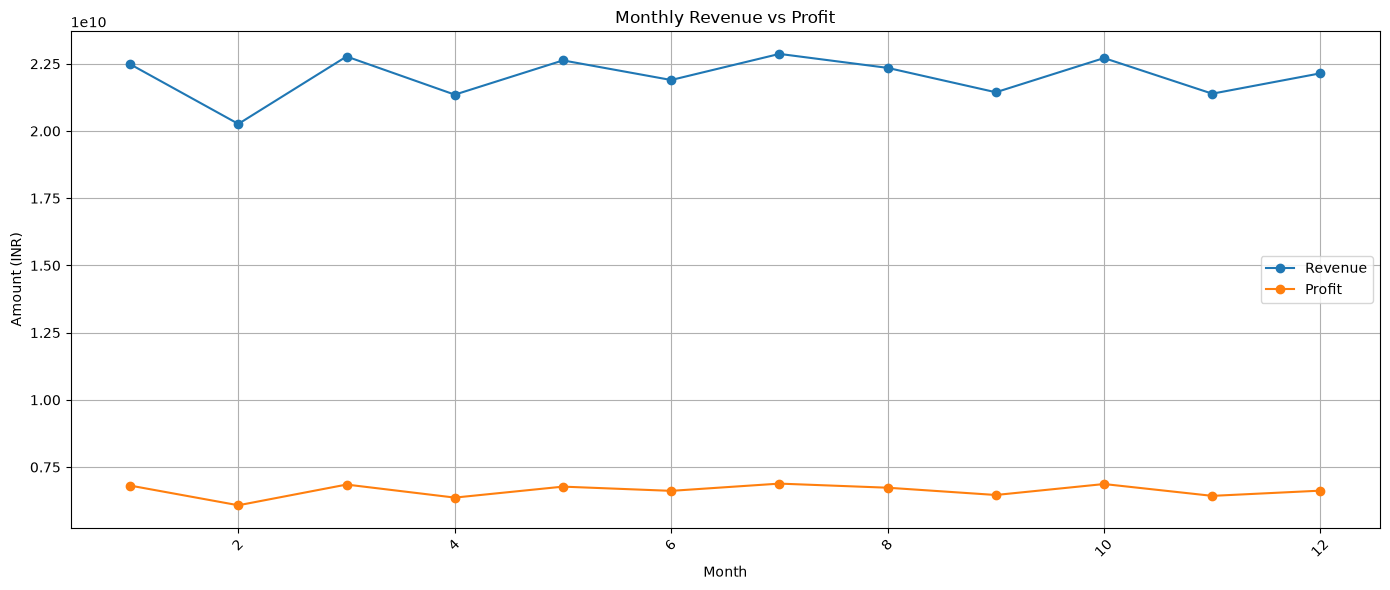

In [ ]:
monthly_comparison = df.groupby('month')[
    ['revenue_inr', 'profit_inr']
].sum()

monthly_comparison.plot(
    kind='line',
    marker='o',
    figsize=(14, 6)
)

plt.title("Monthly Revenue vs Profit")
plt.xlabel("Month")
plt.ylabel("Amount (INR)")
plt.legend(["Revenue", "Profit"])
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

# 27.Highest and Lowest Product-Month Combinations

In [ ]:
highest = monthly_product_sales.stack().idxmax()
lowest = monthly_product_sales.stack().idxmin()

print("\nHighest Product-Month Sales:")
print("Month:", highest[0])
print("Product:", highest[1])
print("Units Sold:", monthly_product_sales.loc[highest])

print("\nLowest Product-Month Sales:")
print("Month:", lowest[0])
print("Product:", lowest[1])
print("Units Sold:", monthly_product_sales.loc[lowest])



Highest Product-Month Sales:
Month: 1
Product: Beauty
Units Sold: 1376699

Lowest Product-Month Sales:
Month: 2
Product: Sports
Units Sold: 1142724


# 28.Final Business Summary


In [ ]:
print("\n========== NEXUS BUSINESS SUMMARY ==========")

print("Best Selling Product:", product_sales.idxmax())

print("Highest Sales Month:", monthly_sales.idxmax())

print("Maximum Profit Month:", monthly_profit.idxmax())

print("Lowest Sales Month:", monthly_sales.idxmin())

print("Lowest Profit Month:", monthly_profit.idxmin())

print("============================================")



========== NEXUS BUSINESS SUMMARY ==========
Best Selling Product: Electronics
Highest Sales Month: 1
Maximum Profit Month: 7
Lowest Sales Month: 2
Lowest Profit Month: 2
